In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.tree import DecisionTreeClassifier, plot_tree

import warnings
warnings.filterwarnings('ignore')

In [2]:
X,y = make_classification(n_features = 5, n_redundant = 0, n_informative = 5, n_clusters_per_class=1)

In [3]:
df = pd.DataFrame(X, columns = ['Feature1','Feature2', 'Feature3', 'Feature4', 'Feature5'])
df['Target'] = y
df.head()

,Feature1,Feature2,Feature3,Feature4,Feature5,Target
0,0.899088,-3.709814,0.022265,0.597738,0.959600,1
1,1.378672,-1.648509,-0.638217,1.082275,-1.800498,1
2,0.237572,0.731678,-3.204309,-0.416643,-1.645716,0
3,1.512017,2.717782,-4.360593,-1.308541,-0.969082,0
4,2.700358,-1.882083,-1.278834,-0.232599,-1.413006,1


In [4]:
df.shape

(100, 6)

## Function For Row Sampling

In [5]:
def row_sampling(df, sampling_rate):
  return df.sample(int(sampling_rate*df.shape[0]), replace = True)


## Function For Column Sampling

In [6]:
def col_sampling(df, sampling_rate):
  features = df.drop(columns = ['Target'])
  cols = features.sample(int(sampling_rate*features.shape[1]), axis = 1)

  return pd.concat([cols, df['Target']], axis = 1)

## Function For Combined Sampling

In [7]:
def combined_sampling(df, row_sampling_rate, col_sampling_rate):
  df1 = row_sampling(df, row_sampling_rate)
  df2 = col_sampling(df1, col_sampling_rate)

  return df2

### Make Different Subset for Each Calssifier

#### Row Sampling

In [8]:
df1 = row_sampling(df, 0.2)
df2 = row_sampling(df, 0.2)
df3 = row_sampling(df, 0.2)

In [9]:
df3.shape

(20, 6)

In [10]:
df3.head()

,Feature1,Feature2,Feature3,Feature4,Feature5,Target
89,0.901517,-1.309231,-1.970179,-0.595311,-0.661190,0
72,0.813334,1.242563,-0.956668,-0.625273,-1.335185,0
2,0.237572,0.731678,-3.204309,-0.416643,-1.645716,0
5,2.592984,0.744100,-2.496939,0.146988,-2.053869,1
14,2.087170,-2.690741,-1.546833,0.820878,-1.309079,1


In [11]:
dt1 = DecisionTreeClassifier()
dt2 = DecisionTreeClassifier()
dt3 = DecisionTreeClassifier()

dt1.fit(df1.drop(columns=['Target']), df1.Target)
dt2.fit(df2.drop(columns=['Target']), df2.Target)
dt3.fit(df3.drop(columns=['Target']), df3.Target)

DecisionTreeClassifier()

[Text(0.6, 0.875, 'x[1] <= 0.351\ngini = 0.495\nsamples = 20\nvalue = [11, 9]'),
 Text(0.4, 0.625, 'x[3] <= -0.541\ngini = 0.375\nsamples = 12\nvalue = [3, 9]'),
 Text(0.5, 0.75, 'True  '),
 Text(0.2, 0.375, 'gini = 0.0\nsamples = 2\nvalue = [2, 0]'),
 Text(0.6, 0.375, 'x[2] <= 0.366\ngini = 0.18\nsamples = 10\nvalue = [1, 9]'),
 Text(0.4, 0.125, 'gini = 0.0\nsamples = 9\nvalue = [0, 9]'),
 Text(0.8, 0.125, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.8, 0.625, 'gini = 0.0\nsamples = 8\nvalue = [8, 0]'),
 Text(0.7, 0.75, '  False')]

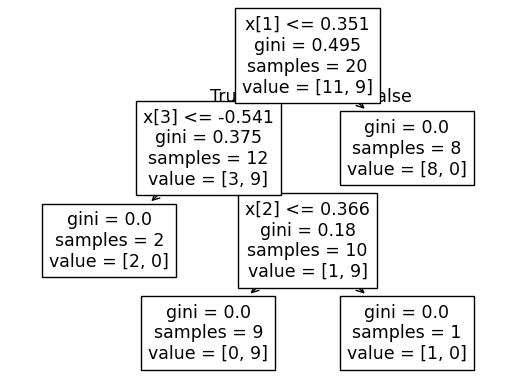

In [12]:
plot_tree(dt1)

[Text(0.4, 0.875, 'x[3] <= -0.58\ngini = 0.495\nsamples = 20\nvalue = [11, 9]'),
 Text(0.2, 0.625, 'gini = 0.0\nsamples = 9\nvalue = [9, 0]'),
 Text(0.30000000000000004, 0.75, 'True  '),
 Text(0.6, 0.625, 'x[0] <= 0.181\ngini = 0.298\nsamples = 11\nvalue = [2, 9]'),
 Text(0.5, 0.75, '  False'),
 Text(0.4, 0.375, 'x[1] <= -0.581\ngini = 0.5\nsamples = 4\nvalue = [2, 2]'),
 Text(0.2, 0.125, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]'),
 Text(0.6, 0.125, 'gini = 0.0\nsamples = 2\nvalue = [2, 0]'),
 Text(0.8, 0.375, 'gini = 0.0\nsamples = 7\nvalue = [0, 7]')]

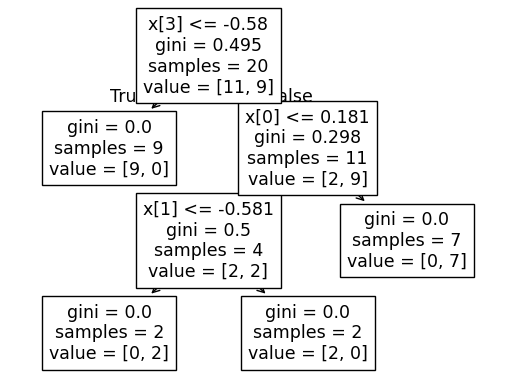

In [13]:
plot_tree(dt2)

[Text(0.4, 0.8333333333333334, 'x[3] <= -0.067\ngini = 0.5\nsamples = 20\nvalue = [10, 10]'),
 Text(0.2, 0.5, 'gini = 0.0\nsamples = 9\nvalue = [9, 0]'),
 Text(0.30000000000000004, 0.6666666666666667, 'True  '),
 Text(0.6, 0.5, 'x[2] <= 0.439\ngini = 0.165\nsamples = 11\nvalue = [1, 10]'),
 Text(0.5, 0.6666666666666667, '  False'),
 Text(0.4, 0.16666666666666666, 'gini = 0.0\nsamples = 10\nvalue = [0, 10]'),
 Text(0.8, 0.16666666666666666, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]')]

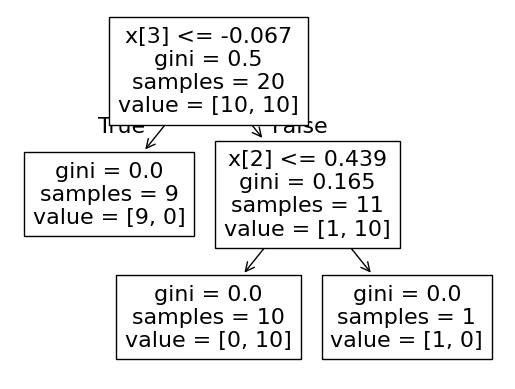

In [14]:
plot_tree(dt3)

In [15]:
df3.head()

,Feature1,Feature2,Feature3,Feature4,Feature5,Target
89,0.901517,-1.309231,-1.970179,-0.595311,-0.661190,0
72,0.813334,1.242563,-0.956668,-0.625273,-1.335185,0
2,0.237572,0.731678,-3.204309,-0.416643,-1.645716,0
5,2.592984,0.744100,-2.496939,0.146988,-2.053869,1
14,2.087170,-2.690741,-1.546833,0.820878,-1.309079,1


# Predict

In [16]:
dt1.predict(np.array([-0.300430,	2.629269,	-1.111983,	-0.901303,	-0.010167]).reshape(1,-1))

array([0])

In [17]:
dt2.predict(np.array([-0.300430,	2.629269,	-1.111983,	-0.901303,	-0.010167]).reshape(1,-1))

array([0])

In [18]:
dt3.predict(np.array([-0.300430,	2.629269,	-1.111983,	-0.901303,	-0.010167]).reshape(1,-1))

array([0])

# Column Sampling

In [32]:
df1 = col_sampling(df, 0.5)
df2 = col_sampling(df, 0.5)
df3 = col_sampling(df, 0.5)

In [33]:
df3.head()

,Feature1,Feature2,Target
0,0.899088,-3.709814,1
1,1.378672,-1.648509,1
2,0.237572,0.731678,0
3,1.512017,2.717782,0
4,2.700358,-1.882083,1


In [34]:
dt1 = DecisionTreeClassifier()
dt2 = DecisionTreeClassifier()
dt3 = DecisionTreeClassifier()

dt1.fit(df1.drop(columns=['Target']), df1.Target)
dt2.fit(df2.drop(columns=['Target']), df2.Target)
dt3.fit(df3.drop(columns=['Target']), df3.Target)

DecisionTreeClassifier()

[Text(0.47282608695652173, 0.9666666666666667, 'x[1] <= -2.848\ngini = 0.5\nsamples = 100\nvalue = [51, 49]'),
 Text(0.21739130434782608, 0.9, 'x[0] <= 2.25\ngini = 0.165\nsamples = 11\nvalue = [10, 1]'),
 Text(0.3451086956521739, 0.9333333333333333, 'True  '),
 Text(0.17391304347826086, 0.8333333333333334, 'gini = 0.0\nsamples = 9\nvalue = [9, 0]'),
 Text(0.2608695652173913, 0.8333333333333334, 'x[0] <= 2.633\ngini = 0.5\nsamples = 2\nvalue = [1, 1]'),
 Text(0.21739130434782608, 0.7666666666666667, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.30434782608695654, 0.7666666666666667, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.7282608695652174, 0.9, 'x[1] <= 0.431\ngini = 0.497\nsamples = 89\nvalue = [41, 48]'),
 Text(0.6005434782608696, 0.9333333333333333, '  False'),
 Text(0.5434782608695652, 0.8333333333333334, 'x[0] <= 1.376\ngini = 0.479\nsamples = 78\nvalue = [31.0, 47.0]'),
 Text(0.391304347826087, 0.7666666666666667, 'x[0] <= 1.286\ngini = 0.499\nsamples = 48\nvalu

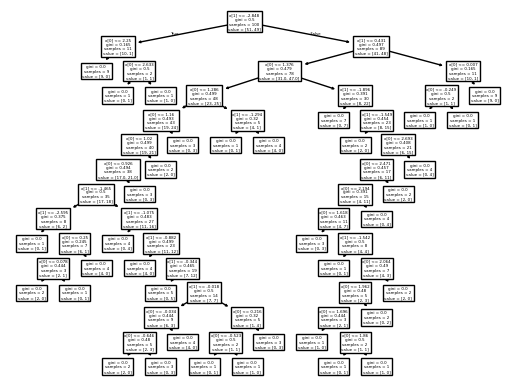

In [35]:
plot_tree(dt1)

[Text(0.6473214285714286, 0.95, 'x[1] <= 1.117\ngini = 0.5\nsamples = 100\nvalue = [51, 49]'),
 Text(0.36607142857142855, 0.85, 'x[1] <= -0.73\ngini = 0.422\nsamples = 66\nvalue = [20, 46]'),
 Text(0.5066964285714286, 0.8999999999999999, 'True  '),
 Text(0.14285714285714285, 0.75, 'x[0] <= -1.942\ngini = 0.17\nsamples = 32\nvalue = [3, 29]'),
 Text(0.07142857142857142, 0.65, 'x[0] <= -2.296\ngini = 0.444\nsamples = 3\nvalue = [2, 1]'),
 Text(0.03571428571428571, 0.55, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.10714285714285714, 0.55, 'x[1] <= -1.414\ngini = 0.5\nsamples = 2\nvalue = [1, 1]'),
 Text(0.07142857142857142, 0.45, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.14285714285714285, 0.45, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.21428571428571427, 0.65, 'x[0] <= -0.258\ngini = 0.067\nsamples = 29\nvalue = [1, 28]'),
 Text(0.17857142857142858, 0.55, 'gini = 0.0\nsamples = 21\nvalue = [0, 21]'),
 Text(0.25, 0.55, 'x[0] <= -0.236\ngini = 0.219\nsamples = 8

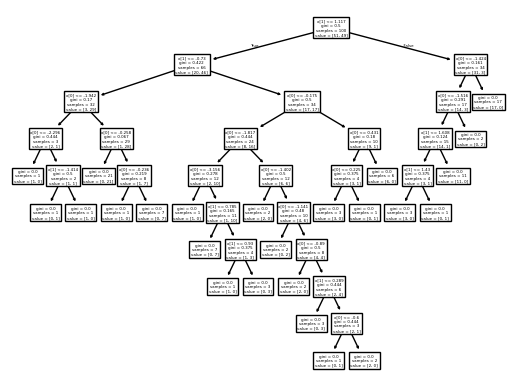

In [36]:
plot_tree(dt2)

[Text(0.6383928571428571, 0.95, 'x[1] <= 1.117\ngini = 0.5\nsamples = 100\nvalue = [51, 49]'),
 Text(0.41964285714285715, 0.85, 'x[0] <= 1.351\ngini = 0.422\nsamples = 66\nvalue = [20, 46]'),
 Text(0.5290178571428571, 0.8999999999999999, 'True  '),
 Text(0.38392857142857145, 0.75, 'x[1] <= -0.73\ngini = 0.496\nsamples = 44\nvalue = [20, 24]'),
 Text(0.16071428571428573, 0.65, 'x[0] <= -0.661\ngini = 0.266\nsamples = 19\nvalue = [3, 16]'),
 Text(0.07142857142857142, 0.55, 'x[0] <= -1.019\ngini = 0.5\nsamples = 2\nvalue = [1, 1]'),
 Text(0.03571428571428571, 0.45, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.10714285714285714, 0.45, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.25, 0.55, 'x[1] <= -2.473\ngini = 0.208\nsamples = 17\nvalue = [2, 15]'),
 Text(0.17857142857142858, 0.45, 'x[1] <= -3.206\ngini = 0.444\nsamples = 3\nvalue = [1, 2]'),
 Text(0.14285714285714285, 0.35, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]'),
 Text(0.21428571428571427, 0.35, 'gini = 0.0\nsamples = 

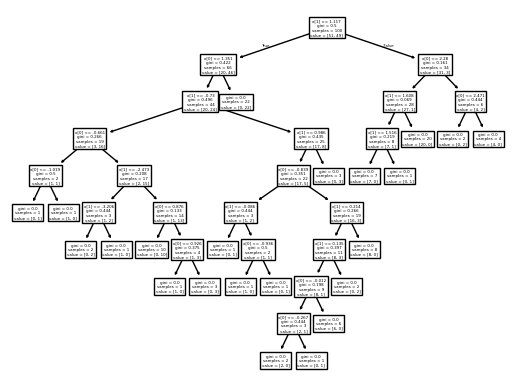

In [37]:
plot_tree(dt3)

In [38]:
df3.head()

,Feature1,Feature2,Target
0,0.899088,-3.709814,1
1,1.378672,-1.648509,1
2,0.237572,0.731678,0
3,1.512017,2.717782,0
4,2.700358,-1.882083,1


In [39]:
dt1.predict(np.array([0.237572,	0.731678]).reshape(1,-1))

array([0])

In [40]:
dt2.predict(np.array([0.237572,	0.731678]).reshape(1,-1))

array([1])

In [41]:
dt3.predict(np.array([0.237572,	0.731678]).reshape(1,-1))

array([0])

# Combined Sampling

In [43]:
df1 = combined_sampling(df, 0.4, 0.5)
df2 = combined_sampling(df, 0.4, 0.5)
df3 = combined_sampling(df, 0.4, 0.5)

In [44]:
dt1 = DecisionTreeClassifier()
dt2 = DecisionTreeClassifier()
dt3 = DecisionTreeClassifier()

dt1.fit(df1.drop(columns=['Target']), df1.Target)
dt2.fit(df2.drop(columns=['Target']), df2.Target)
dt3.fit(df3.drop(columns=['Target']), df3.Target)

DecisionTreeClassifier()

[Text(0.5, 0.95, 'x[0] <= 1.016\ngini = 0.499\nsamples = 40\nvalue = [19, 21]'),
 Text(0.2, 0.85, 'x[0] <= -1.634\ngini = 0.426\nsamples = 26\nvalue = [18, 8]'),
 Text(0.35, 0.8999999999999999, 'True  '),
 Text(0.1, 0.75, 'gini = 0.0\nsamples = 9\nvalue = [9, 0]'),
 Text(0.3, 0.75, 'x[1] <= 1.767\ngini = 0.498\nsamples = 17\nvalue = [9, 8]'),
 Text(0.2, 0.65, 'x[0] <= -0.045\ngini = 0.426\nsamples = 13\nvalue = [9, 4]'),
 Text(0.1, 0.55, 'gini = 0.0\nsamples = 3\nvalue = [3, 0]'),
 Text(0.3, 0.55, 'x[0] <= 0.204\ngini = 0.48\nsamples = 10\nvalue = [6, 4]'),
 Text(0.2, 0.45, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]'),
 Text(0.4, 0.45, 'x[1] <= -0.201\ngini = 0.375\nsamples = 8\nvalue = [6, 2]'),
 Text(0.3, 0.35, 'gini = 0.0\nsamples = 2\nvalue = [2, 0]'),
 Text(0.5, 0.35, 'x[1] <= 0.412\ngini = 0.444\nsamples = 6\nvalue = [4, 2]'),
 Text(0.4, 0.25, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.6, 0.25, 'x[1] <= 0.825\ngini = 0.32\nsamples = 5\nvalue = [4, 1]'),
 Text(0.5, 0.15, 'g

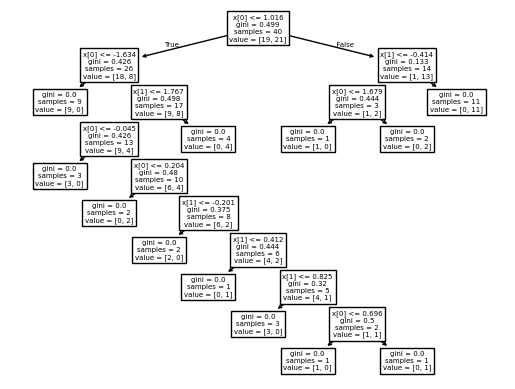

In [45]:
plot_tree(dt1)

[Text(0.4444444444444444, 0.9166666666666666, 'x[0] <= 0.376\ngini = 0.499\nsamples = 40\nvalue = [19, 21]'),
 Text(0.2222222222222222, 0.75, 'x[0] <= -0.73\ngini = 0.298\nsamples = 22\nvalue = [4, 18]'),
 Text(0.3333333333333333, 0.8333333333333333, 'True  '),
 Text(0.1111111111111111, 0.5833333333333334, 'gini = 0.0\nsamples = 12\nvalue = [0, 12]'),
 Text(0.3333333333333333, 0.5833333333333334, 'x[0] <= -0.363\ngini = 0.48\nsamples = 10\nvalue = [4, 6]'),
 Text(0.2222222222222222, 0.4166666666666667, 'gini = 0.0\nsamples = 4\nvalue = [4, 0]'),
 Text(0.4444444444444444, 0.4166666666666667, 'gini = 0.0\nsamples = 6\nvalue = [0, 6]'),
 Text(0.6666666666666666, 0.75, 'x[1] <= -2.254\ngini = 0.278\nsamples = 18\nvalue = [15, 3]'),
 Text(0.5555555555555556, 0.8333333333333333, '  False'),
 Text(0.5555555555555556, 0.5833333333333334, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.7777777777777778, 0.5833333333333334, 'x[0] <= 1.289\ngini = 0.208\nsamples = 17\nvalue = [15, 2]'),
 Text

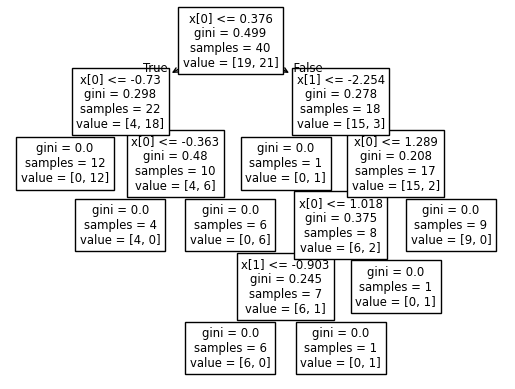

In [46]:
plot_tree(dt2)

[Text(0.45454545454545453, 0.9375, 'x[0] <= -0.134\ngini = 0.5\nsamples = 40\nvalue = [20, 20]'),
 Text(0.18181818181818182, 0.8125, 'x[1] <= -1.767\ngini = 0.198\nsamples = 18\nvalue = [16, 2]'),
 Text(0.3181818181818182, 0.875, 'True  '),
 Text(0.09090909090909091, 0.6875, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.2727272727272727, 0.6875, 'x[0] <= -0.541\ngini = 0.111\nsamples = 17\nvalue = [16, 1]'),
 Text(0.18181818181818182, 0.5625, 'gini = 0.0\nsamples = 14\nvalue = [14, 0]'),
 Text(0.36363636363636365, 0.5625, 'x[0] <= -0.47\ngini = 0.444\nsamples = 3\nvalue = [2, 1]'),
 Text(0.2727272727272727, 0.4375, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.45454545454545453, 0.4375, 'gini = 0.0\nsamples = 2\nvalue = [2, 0]'),
 Text(0.7272727272727273, 0.8125, 'x[1] <= -0.714\ngini = 0.298\nsamples = 22\nvalue = [4, 18]'),
 Text(0.5909090909090909, 0.875, '  False'),
 Text(0.6363636363636364, 0.6875, 'gini = 0.0\nsamples = 10\nvalue = [0, 10]'),
 Text(0.8181818181818182,

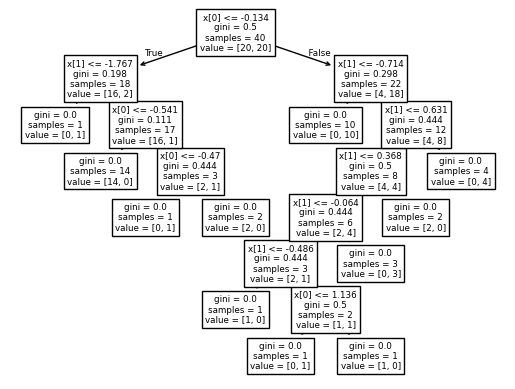

In [47]:
plot_tree(dt3)

In [48]:
df3.head()

,Feature4,Feature2,Target
77,0.506763,-3.005945,1
51,2.078035,0.162340,1
13,2.250386,0.736140,1
49,1.006597,1.551316,1
47,1.295349,0.529157,0


In [49]:
dt1.predict(np.array([1.295349,	0.529157]).reshape(1,-1))

array([1])

In [50]:
dt2.predict(np.array([1.295349,	0.529157]).reshape(1,-1))

array([0])

In [51]:
dt3.predict(np.array([1.295349,	0.529157]).reshape(1,-1))

array([0])